<a href="https://colab.research.google.com/github/A1704/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/A1704/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

**Lane:** Refresh / Content Opportunity Scoring  
**Purpose:** Turn the Week 5 client-grouped model output into a ranked, human-reviewed content action queue.

This is a research prototype and decision-support workflow, not a production automation system. It ranks only the held-out test clients from the validated Week 5 split so the queue is based on out-of-sample predictions. It does not include client identifiers, URLs, titles, domains, or private queries.

> **Evidence boundary:** the target is a historical declining-trend label. A high score means the model ranked an item as more similar to historically declining items. It does not prove that refreshing the item will improve traffic, engagement, or revenue. Causal impact requires a controlled experiment.


## 1. Ranked actions + reason codes

### Ranking rule

Use the Week 5 model selected on the client-grouped validation comparison. The queue is ranked by its predicted probability for the historical decline label, descending. This probability is a ranking score, **not a calibrated probability of refresh success**.

The notebook recreates the Week 5 preprocessing and 80/20 client-grouped holdout (25 train clients / 7 test clients in the recorded run). It scores only the held-out test rows. The label is used for validation metrics and the descriptive decay audit only; it is never used to create action flags or reason codes.

### Reason codes

| Code | Operational meaning |
|---|---|
| `model_decline_risk` | Model score ≥ 0.65; a review threshold, not a calibrated confidence band |
| `visible_search_demand` | At least 500 impressions in the trailing 90 days |
| `stale_content_180d` | No update recorded for at least 180 days |
| `ctr_review_candidate` | At least 500 impressions, average position 1–20, and CTR below 0.5% |
| `engagement_review_candidate` | At least 30 sessions and engagement rate or scroll rate between 0% and 30% |

The rate fields in this dataset are stored as percentage points multiplied by 100 (for example, `0.5` means 0.5%). The thresholds are triage rules, not universal editorial standards.

### Archetype → action mapping

| Archetype | Suggested action | What the reviewer investigates |
|---|---|---|
| `snippet_or_intent_gap` | `refresh_and_review_ctr` | Search intent match, title/snippet accuracy, SERP competition |
| `engagement_experience_gap` | `refresh_and_review_engagement` | Opening, structure, readability, usefulness, page experience |
| `stale_visible_content` | `refresh_candidate_human_review` | Factual currency, outdated examples, intent changes, authoritative sources |
| `general_decline_risk` | `audit_search_intent` | Whether the historical signal is meaningful and what changed |
| `monitor_only` | `monitor` | No immediate refresh recommendation; retain for later review |

The action is a **review task**, not an instruction to edit or publish. More than one reason code can apply; the action mapping uses a documented priority order in the code.


In [ ]:
# Recreate the Week 5 client-grouped evaluation and generate an out-of-sample queue.
# No client IDs or page-level private fields are exported.

from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

RANDOM_STATE = 42

# Find the repository/data in Colab or a local checkout.
REPO_DIR = Path("/content/flyrank-ml-internship")
DATA_PATH = Path("data/raw/content_refresh_anonymized.csv")
if not DATA_PATH.exists() and (REPO_DIR / "data/raw/content_refresh_anonymized.csv").exists():
    DATA_PATH = REPO_DIR / "data/raw/content_refresh_anonymized.csv"
if not DATA_PATH.exists():
    if not REPO_DIR.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/A1704/flyrank-ml-internship.git", str(REPO_DIR)],
            check=True
        )
    DATA_PATH = REPO_DIR / "data/raw/content_refresh_anonymized.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Could not locate the anonymized starter dataset.")

raw_df = pd.read_csv(DATA_PATH)
required = [
    "content_id", "client_id", "trend_direction", "impressions_90d",
    "days_since_last_update", "avg_position", "word_count",
    "content_age_days", "sessions_90d", "ctr", "engagement_rate", "scroll_rate"
]
missing = [c for c in required if c not in raw_df.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")

# Historical label: used only for model validation and descriptive audit.
raw_df["trend_direction"] = raw_df["trend_direction"].fillna("unknown").astype(str)
raw_df["is_declining_label"] = raw_df["trend_direction"].str.lower().eq("down").astype(int)

df = raw_df[
    (pd.to_numeric(raw_df["impressions_90d"], errors="coerce") > 0)
    & (pd.to_numeric(raw_df["content_age_days"], errors="coerce") >= 90)
].drop_duplicates("content_id").reset_index(drop=True).copy()

numeric_features = [
    "search_volume", "competition", "cpc", "word_count", "char_count",
    "days_with_impressions", "days_with_sessions", "content_age_days",
    "days_since_last_update", "ctr", "avg_position",
    "engagement_rate", "scroll_rate", "ai_traffic_pct"
]
log_source = {
    "log_impressions_90d": "impressions_90d",
    "log_clicks_90d": "clicks_90d",
    "log_sessions_90d": "sessions_90d",
    "log_ai_sessions_90d": "ai_sessions_90d",
}
for new_col, source_col in log_source.items():
    if source_col in df.columns:
        df[new_col] = np.log1p(
            pd.to_numeric(df[source_col], errors="coerce").clip(lower=0)
        )
        numeric_features.append(new_col)

categorical_features = [
    "competition_level", "content_type", "main_intent",
    "age_tier", "freshness_tier", "word_count_tier",
    "impression_tier", "position_tier"
]
numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]

missing_flag_features = []
for c in numeric_features:
    flag = f"has_value_{c}"
    df[flag] = df[c].notna().astype(int)
    missing_flag_features.append(flag)

feature_columns = numeric_features + categorical_features + missing_flag_features
X = df[feature_columns].copy()
y = df["is_declining_label"].astype(int)
groups = df["client_id"].fillna("unknown").astype(str)

if y.nunique() != 2 or groups.nunique() < 5:
    raise ValueError("The target needs two classes and at least five distinct clients.")

split_found = False
for seed in range(RANDOM_STATE, RANDOM_STATE + 100):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=seed)
    train_idx, test_idx = next(splitter.split(X, y, groups))
    if y.iloc[train_idx].nunique() == 2 and y.iloc[test_idx].nunique() == 2:
        split_found = True
        break
if not split_found:
    raise ValueError("Could not create a valid client-grouped split; do not fall back to a row split.")

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])
assert train_clients.isdisjoint(test_clients)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features + missing_flag_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=25,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1
    )
}

def precision_at_k(y_true, scores, k):
    y_arr = np.asarray(y_true)
    scores_arr = np.asarray(scores)
    n = min(k, len(y_arr))
    top_idx = np.argsort(-scores_arr, kind="stable")[:n]
    return float(y_arr[top_idx].mean()) if n else float("nan")

fitted_models = {}
test_scores = {}
metric_rows = []
for model_name, classifier in models.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    model.fit(X_train, y_train)
    scores = model.predict_proba(X_test)[:, 1]
    fitted_models[model_name] = model
    test_scores[model_name] = scores
    metric_rows.append({
        "model": model_name,
        "precision_at_20": precision_at_k(y_test, scores, 20),
        "precision_at_50": precision_at_k(y_test, scores, 50),
        "precision_at_100": precision_at_k(y_test, scores, 100),
        "average_precision": average_precision_score(y_test, scores),
        "roc_auc": roc_auc_score(y_test, scores)
    })

model_metrics = pd.DataFrame(metric_rows).sort_values(
    ["precision_at_50", "average_precision", "roc_auc"], ascending=False
).reset_index(drop=True)
display(model_metrics.round(3))

# Week 5 selected Logistic Regression using the client-grouped evaluation.
# Do not select a model using the held-out test-set results here.
best_name = "Logistic Regression"
best_model = fitted_models[best_name]
best_scores = test_scores[best_name]
print("Selected Week 5 model:", best_name)
print("Rows in grouped test set:", len(test_idx))
print("Train clients:", len(train_clients), "| Test clients:", len(test_clients))
print("Client overlap:", len(train_clients & test_clients))
print("Selected-model Precision@50:", round(precision_at_k(y_test, best_scores, 50), 3))

# Create action flags from observable fields + model score only.
# Do not use trend_direction, trend_pct, or is_declining_label here.
scored = df.iloc[test_idx].copy().reset_index(drop=True)
scored["decline_score"] = best_scores

scored["flag_model_decline_risk"] = scored["decline_score"] >= 0.65
scored["flag_visible_search_demand"] = scored["impressions_90d"] >= 500
scored["flag_stale_content_180d"] = scored["days_since_last_update"] >= 180
scored["flag_ctr_review_candidate"] = (
    (scored["impressions_90d"] >= 500)
    & (scored["avg_position"] > 0)
    & (scored["avg_position"] <= 20)
    & (scored["ctr"] < 0.5)
)
scored["flag_engagement_review_candidate"] = (
    (scored["sessions_90d"] >= 30)
    & (
        ((scored["engagement_rate"] > 0) & (scored["engagement_rate"] < 30))
        | ((scored["scroll_rate"] > 0) & (scored["scroll_rate"] < 30))
    )
)

def build_reason_codes(row):
    reasons = []
    if row["flag_model_decline_risk"]:
        reasons.append("model_decline_risk")
    if row["flag_visible_search_demand"]:
        reasons.append("visible_search_demand")
    if row["flag_stale_content_180d"]:
        reasons.append("stale_content_180d")
    if row["flag_ctr_review_candidate"]:
        reasons.append("ctr_review_candidate")
    if row["flag_engagement_review_candidate"]:
        reasons.append("engagement_review_candidate")
    return "|".join(reasons) if reasons else "no_specific_review_signal"

def map_action(row):
    risk = row["flag_model_decline_risk"]
    if risk and row["flag_ctr_review_candidate"]:
        return "refresh_and_review_ctr", "snippet_or_intent_gap"
    if risk and row["flag_engagement_review_candidate"]:
        return "refresh_and_review_engagement", "engagement_experience_gap"
    if risk and row["flag_visible_search_demand"] and row["flag_stale_content_180d"]:
        return "refresh_candidate_human_review", "stale_visible_content"
    if risk and row["flag_visible_search_demand"]:
        return "audit_search_intent", "general_decline_risk"
    if risk:
        return "monitor_model_signal", "general_decline_risk"
    return "monitor", "monitor_only"

scored["reason_codes"] = scored.apply(build_reason_codes, axis=1)
action_map = scored.apply(map_action, axis=1, result_type="expand")
scored["suggested_action"] = action_map[0]
scored["archetype"] = action_map[1]

action_notes = {
    "snippet_or_intent_gap": "Check query intent, title/snippet accuracy, and the live search results before editing.",
    "engagement_experience_gap": "Review the opening, structure, readability, usefulness, and page experience.",
    "stale_visible_content": "Verify facts, dates, examples, source quality, and whether the search intent has changed.",
    "general_decline_risk": "Investigate what changed; do not assume a refresh is the correct intervention.",
    "monitor_only": "No immediate edit; retain for a later review cycle."
}
scored["human_review_note"] = scored["archetype"].map(action_notes)

queue_columns = [
    "content_id", "decline_score", "suggested_action", "archetype",
    "reason_codes", "impressions_90d", "sessions_90d",
    "days_since_last_update", "avg_position", "ctr",
    "engagement_rate", "scroll_rate", "word_count", "human_review_note"
]
queue = scored.sort_values("decline_score", ascending=False, kind="stable")[queue_columns].copy()
queue.insert(0, "rank", np.arange(1, len(queue) + 1))

# Privacy and integrity checks: no client IDs, URLs, titles, or target labels.
assert queue["content_id"].is_unique
assert queue["rank"].is_unique
assert "client_id" not in queue.columns
assert "trend_direction" not in queue.columns
assert "trend_pct" not in queue.columns
assert "is_declining_label" not in queue.columns
assert queue["decline_score"].between(0, 1).all()

print("Queue rows:", len(queue))
print("Unique pseudonymous content IDs:", queue["content_id"].nunique())
print("Queue contains client IDs or target labels: no")
display(queue.head(15))


,model,precision_at_20,precision_at_50,precision_at_100,average_precision,roc_auc
0,Logistic Regression,0.70,0.72,0.71,0.605,0.615
1,Random Forest,0.55,0.56,0.56,0.592,0.611


Selected Week 5 model: Logistic Regression
Rows in grouped test set: 6163
Train clients: 25 | Test clients: 7
Client overlap: 0
Selected-model Precision@50: 0.72
Queue rows: 6163
Unique pseudonymous content IDs: 6163
Queue contains client IDs or target labels: no


,rank,content_id,decline_score,suggested_action,archetype,reason_codes,impressions_90d,sessions_90d,days_since_last_update,avg_position,ctr,engagement_rate,scroll_rate,word_count,human_review_note
330,1,content_a928cb66d230,0.950656,monitor_model_signal,general_decline_risk,model_decline_risk,128,3,20,4.2,0.00,0.0,300.00,2616.0,Investigate what changed; do not assume a refr...
5482,2,content_7be5f150dc65,0.946053,monitor_model_signal,general_decline_risk,model_decline_risk,290,2,20,5.9,0.00,0.0,200.00,2481.0,Investigate what changed; do not assume a refr...
3589,3,content_c82bc0c24241,0.937218,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,13676,3,8,4.3,0.00,0.0,0.00,3099.0,"Check query intent, title/snippet accuracy, an..."
573,4,content_87c007fb5c26,0.934282,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,2463,2,20,6.6,0.00,0.0,100.00,2853.0,"Check query intent, title/snippet accuracy, an..."
4309,5,content_41baf0722ad9,0.932678,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,3115,4,104,12.8,0.00,0.0,25.00,1596.0,"Check query intent, title/snippet accuracy, an..."
126,6,content_5d77d3077984,0.931483,monitor_model_signal,general_decline_risk,model_decline_risk,68,3,20,3.0,0.00,0.0,300.00,2959.0,Investigate what changed; do not assume a refr...
680,7,content_b5e9e6453511,0.925576,monitor_model_signal,general_decline_risk,model_decline_risk,157,2,20,6.1,0.00,0.0,200.00,3024.0,Investigate what changed; do not assume a refr...
1316,8,content_e988c1699454,0.924904,audit_search_intent,general_decline_risk,model_decline_risk|visible_search_demand,2197,4,104,21.5,0.00,0.0,50.00,1353.0,Investigate what changed; do not assume a refr...
1952,9,content_8ba781dafa55,0.921875,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,16156,2,104,9.0,0.00,0.0,0.00,3343.0,"Check query intent, title/snippet accuracy, an..."
2805,10,content_ccf887ee3581,0.920857,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,2993,3,104,5.5,0.03,0.0,33.33,1377.0,"Check query intent, title/snippet accuracy, an..."


### Reading the ranked queue

The first rows are the highest model scores among the held-out clients. The score is useful for ordering a finite review workload, but it is not a measure of expected traffic lift. Reason codes explain which observable checks made an action archetype relevant. An item can rank highly and still be a false positive, so the queue always ends at human review.


## 2. Intended use and limits

### Intended user and workflow

A content strategist or SEO/editorial analyst uses this queue once per review cycle to choose a manageable set of pages for investigation. Start with the top 20–50 rows, check the page and live search context, record accept/reject/defer with a reason, and only then decide whether a human-authored update is justified.

The model is a triage assistant for the anonymized research dataset. It is not a live integration, not a production service, and not a replacement for editorial judgement.

### What the validation supports

The Week 5 experiment used a client-grouped 80/20 split. The recorded run had 23,837 training rows, 6,163 test rows, 25 train clients, seven test clients, and zero client overlap. Logistic Regression achieved Precision@50 = 0.720, average precision = 0.605, and ROC-AUC = 0.615 in the recorded grouped evaluation. The notebook recomputes these values so the paper can cite the executed metrics JSON.

Precision@50 is the primary ranking metric for a top-50 review queue. ROC-AUC of 0.615 indicates limited overall discrimination. The model was compared on the same held-out set used to select the best model, so the selected score can be optimistic. This is not a separate untouched final test.

### Limits

- The label describes historical decline (`trend_direction == "down"`), not future recovery after a refresh.
- The starter data is a 90-day snapshot, not a full causal before/after experiment.
- A client-grouped holdout tests generalization to held-out clients in this dataset; it does not prove performance on all future clients or time periods.
- The model may learn client/content mix patterns that shift over time.
- CTR, engagement, scroll, position, and impressions are measurement proxies with known data quirks; inspect the data dictionary before interpreting them.
- The action thresholds (0.65 score, 500 impressions, 180 days, position 1–20, rate below 0.5/30) are operational screening choices, not optimized universal cutoffs.
- A high score can still be wrong; a low score does not mean a page is healthy.

### Decay / refresh insight

The earlier signal audit showed a non-monotonic relationship between update age and the historical decline label: 0–90 days had a 51.2% decline rate (n=20,655), 91–180 days had 61.1% (n=9,171), and 181+ days had 47.1% (n=174). The oldest bucket is small and does not support a strong conclusion. The practical lesson is **not** “older pages always decline more.” The middle-age bucket deserves attention in this sample, while age alone is not a refresh instruction. The notebook recomputes the descriptive rates from the raw data and exports the exact counts.

These are observed associations in one anonymized dataset. They do not show that refreshing content prevents or reverses decline.


In [ ]:
# Descriptive decay audit. The target is used here only to summarize historical rates,
# never as a model feature, queue score, reason code, or action trigger.

raw_df["freshness_bucket"] = pd.cut(
    pd.to_numeric(raw_df["days_since_last_update"], errors="coerce"),
    bins=[-np.inf, 90, 180, np.inf],
    labels=["0–90 days", "91–180 days", "181+ days"]
)
decay_summary = (
    raw_df.groupby("freshness_bucket", observed=False)
    .agg(
        n=("is_declining_label", "size"),
        decline_rate=("is_declining_label", "mean")
    )
    .reset_index()
)
decay_summary["decline_rate_pct"] = decay_summary["decline_rate"] * 100
display(decay_summary[["freshness_bucket", "n", "decline_rate_pct"]].round(1))

print(
    "Interpretation: describe the pattern, do not infer a refresh effect. "
    "The 181+ day bucket is small; age alone is not a sufficient action rule."
)


,freshness_bucket,n,decline_rate_pct
0,0–90 days,20655,51.2
1,91–180 days,9171,61.1
2,181+ days,174,47.1


Interpretation: describe the pattern, do not infer a refresh effect. The 181+ day bucket is small; age alone is not a sufficient action rule.


## 3. Human review + the no-go list

### Mandatory human review before any action

For every proposed refresh, a reviewer must:

1. Open the actual page and confirm it exists, is indexable, and is not a duplicate/canonical issue.
2. Check the current query intent and search results; verify that the page still serves the intended audience.
3. Check factual accuracy, dates, examples, links, citations, and whether specialist review is required.
4. Review business value and conversion role, not just impressions or the model score.
5. Check seasonality, recent algorithm/site changes, cannibalization, and competing pages.
6. Decide whether to refresh, monitor, consolidate, or take no action; record the reason and reviewer/date.
7. If a refresh is approved, have an editor own the changes and a second person review sensitive claims.

A reviewer may reject a high-ranked item. That is a valid outcome and should be logged, not treated as a model failure to hide.

### What must NOT be automated

- Do not auto-edit, rewrite, publish, unpublish, delete, redirect, canonicalize, or noindex pages.
- Do not auto-change titles, meta descriptions, structured data, internal links, or claims.
- Do not auto-assign budgets, commissions, editorial owners, or deadlines.
- Do not generate or approve medical, legal, financial, safety, or other regulated claims without qualified review.
- Do not treat the score as a traffic forecast, revenue estimate, causal effect, or guaranteed uplift.
- Do not send client-facing recommendations from this research queue without an authorized human checking context and permissions.
- Do not export client IDs, names, domains, URLs, titles, keywords, or private queries.

This notebook deliberately produces a review queue only. It does not perform content changes or call external publishing systems.


In [ ]:
# Human-review policy as a compact checklist that can be reused by the paper/team.
human_review_checks = [
    "Page exists, is indexable, and is not a duplicate/canonical issue",
    "Current query intent and live search results checked",
    "Facts, dates, examples, sources, and links verified",
    "Business value and conversion role considered",
    "Seasonality, cannibalization, and competing pages checked",
    "Decision (refresh / monitor / consolidate / no action) recorded with reason",
    "Editor owns any change; sensitive claims receive qualified second review"
]
no_automation = [
    "No automatic editing, publishing, deleting, redirecting, canonicalizing, or noindexing",
    "No automatic title/meta/schema/internal-link changes",
    "No automatic budget, owner, or deadline assignment",
    "No automated approval of regulated or high-impact claims",
    "No causal, revenue, or traffic-uplift claims from this score",
    "No client-facing action without authorized human review"
]
print("Mandatory human checks:", len(human_review_checks))
for item in human_review_checks:
    print("•", item)
print("\nNo-go automation rules:", len(no_automation))
for item in no_automation:
    print("•", item)


Mandatory human checks: 7
• Page exists, is indexable, and is not a duplicate/canonical issue
• Current query intent and live search results checked
• Facts, dates, examples, sources, and links verified
• Business value and conversion role considered
• Seasonality, cannibalization, and competing pages checked
• Decision (refresh / monitor / consolidate / no action) recorded with reason
• Editor owns any change; sensitive claims receive qualified second review

No-go automation rules: 6
• No automatic editing, publishing, deleting, redirecting, canonicalizing, or noindexing
• No automatic title/meta/schema/internal-link changes
• No automatic budget, owner, or deadline assignment
• No automated approval of regulated or high-impact claims
• No causal, revenue, or traffic-uplift claims from this score
• No client-facing action without authorized human review


## 4. Monitoring / retrain triggers

### Lightweight monitoring

For a limited pilot, review the queue monthly and record:

- Queue size and action/archetype mix.
- Score distribution and the share above the 0.65 review threshold.
- Missingness and new/unseen categories in the input fields.
- Reviewer acceptance, rejection, defer rates, and reasons.
- Once labels mature, Precision@50 and average precision on a new time window, with client grouping where possible.

### Proposed review / retrain triggers

These are practical guardrails for a pilot, not statistically validated alarm thresholds:

- **Data quality review:** required field missingness or unknown-category rates rise by 10 percentage points from the notebook baseline, or the source schema/measurement definition changes.
- **Performance review:** Precision@50 falls by at least 0.10 absolute versus the grouped-validation reference in two consecutive evaluation windows, with at least 50 newly labeled items per window. Treat small samples cautiously.
- **Population review:** historical decline-label prevalence shifts by more than 20% relative to the reference period, or the client/content mix changes materially.
- **Retraining review:** only after enough newly labeled, quality-checked data is available and a fresh client-grouped evaluation can be run. Keep a separate untouched time-based or client-held-out test where feasible.

A trigger means investigate and validate; it does not mean automatically retrain or deploy. Do not retrain on one bad week or silently change thresholds to improve the dashboard.


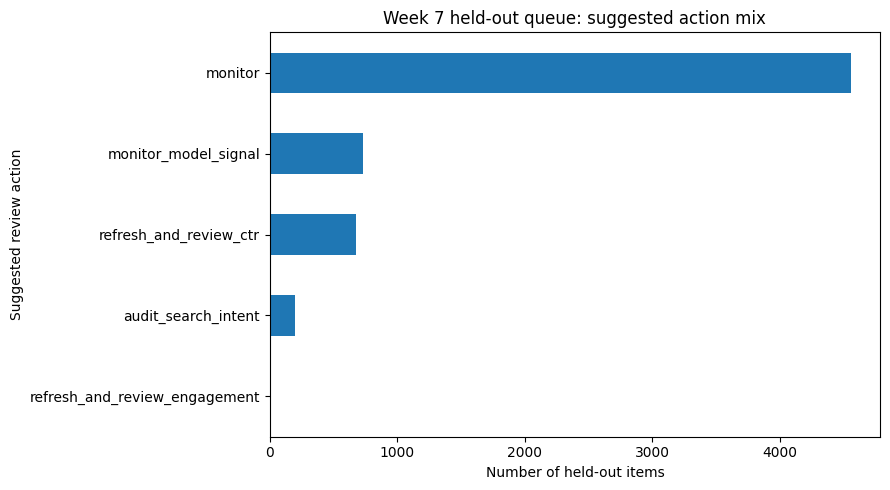

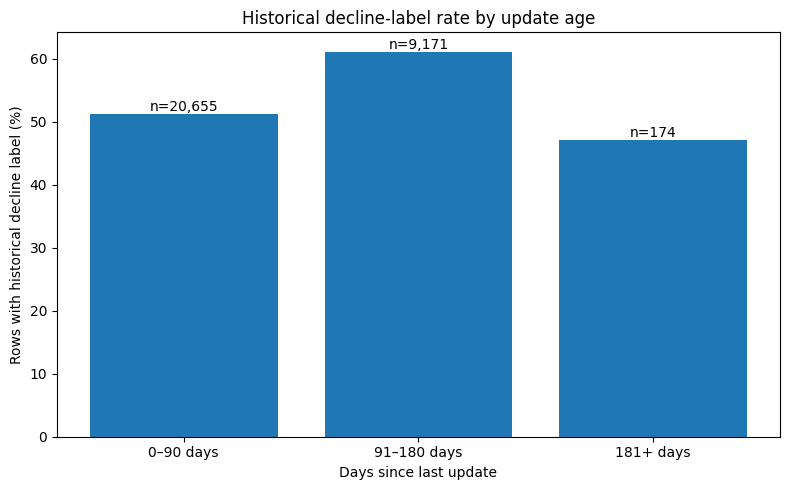

Metrics JSON: /content/flyrank-ml-internship/work/outputs/w07_action_playbook_metrics.json
Action-mix figure: /content/flyrank-ml-internship/work/figures/w07_action_mix.png
Freshness/decay figure: /content/flyrank-ml-internship/work/figures/w07_decline_by_freshness.png
Top-50 review time assumption: 4.17–8.33 hours.


In [ ]:
# Save a reproducible metrics receipt and reusable figures.
from pathlib import Path
import json
import matplotlib.pyplot as plt

REPO_ROOT = DATA_PATH.resolve().parents[2]
OUTPUT_DIR = REPO_ROOT / "work" / "outputs"
FIGURE_DIR = REPO_ROOT / "work" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

action_counts = queue["suggested_action"].value_counts().sort_values(ascending=False)
archetype_counts = queue["archetype"].value_counts().sort_values(ascending=False)

# The queue is generated from held-out test predictions only.
top50_idx = np.argsort(-best_scores, kind="stable")[:min(50, len(best_scores))]
precision_at_50 = float(np.asarray(y_test)[top50_idx].mean())

metrics_receipt = {
    "assignment": "ML-10 — Content Action Playbook",
    "dataset": "data/raw/content_refresh_anonymized.csv",
    "dataset_rows_raw": int(len(raw_df)),
    "dataset_clients_raw": int(raw_df["client_id"].nunique()),
    "model_rows_after_week5_filter": int(len(df)),
    "target": "is_declining_label derived from trend_direction == 'down'",
    "split": {
        "method": "GroupShuffleSplit",
        "train_rows": int(len(train_idx)),
        "test_rows": int(len(test_idx)),
        "train_clients": int(len(train_clients)),
        "test_clients": int(len(test_clients)),
        "client_overlap": int(len(train_clients & test_clients))
    },
    "selected_model": best_name,
    "selected_model_metrics": {
        "precision_at_20": float(precision_at_k(y_test, best_scores, 20)),
        "precision_at_50": float(precision_at_k(y_test, best_scores, 50)),
        "precision_at_100": float(precision_at_k(y_test, best_scores, 100)),
        "top50_precision_check": precision_at_50,
        "average_precision": float(average_precision_score(y_test, best_scores)),
        "roc_auc": float(roc_auc_score(y_test, best_scores))
    },
    "model_comparison": model_metrics.to_dict(orient="records"),
    "queue": {
        "rows": int(len(queue)),
        "ranked_on": "selected model score, descending",
        "scored_population": "held-out test rows only",
        "contains_client_ids": False,
        "contains_target_label": False,
        "action_counts": {str(k): int(v) for k, v in action_counts.items()},
        "archetype_counts": {str(k): int(v) for k, v in archetype_counts.items()}
    },
    "freshness_decay_audit": [
        {
            "bucket": str(row.freshness_bucket),
            "n": int(row.n),
            "decline_rate": float(row.decline_rate)
        }
        for row in decay_summary.itertuples(index=False)
    ],
    "operational_assumptions": {
        "review_batch": 50,
        "minutes_per_human_review_item_low": 5,
        "minutes_per_human_review_item_high": 10,
        "estimated_top50_review_hours_low": round(50 * 5 / 60, 2),
        "estimated_top50_review_hours_high": round(50 * 10 / 60, 2),
        "note": "Planning assumption only; not an observed cost or ROI estimate."
    },
    "limitations": [
        "Historical decline prediction is not a causal estimate of refresh impact.",
        "The best model was selected on the same held-out set used for evaluation; selected performance may be optimistic.",
        "The grouped split tests held-out clients, not future time periods or all possible clients.",
        "Thresholds are triage heuristics and are not universal or calibrated.",
        "Every action requires human review; no content changes are automated."
    ]
}

metrics_path = OUTPUT_DIR / "w07_action_playbook_metrics.json"
metrics_path.write_text(json.dumps(metrics_receipt, indent=2), encoding="utf-8")

# Figure 1: queue action mix.
fig, ax = plt.subplots(figsize=(9, 5))
action_counts.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Week 7 held-out queue: suggested action mix")
ax.set_xlabel("Number of held-out items")
ax.set_ylabel("Suggested review action")
fig.tight_layout()
action_figure = FIGURE_DIR / "w07_action_mix.png"
fig.savefig(action_figure, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: historical decline rate by update-age bucket.
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    decay_summary["freshness_bucket"].astype(str),
    decay_summary["decline_rate_pct"]
)
ax.set_title("Historical decline-label rate by update age")
ax.set_xlabel("Days since last update")
ax.set_ylabel("Rows with historical decline label (%)")
for bar, n in zip(bars, decay_summary["n"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"n={int(n):,}",
        ha="center",
        va="bottom"
    )
fig.tight_layout()
decay_figure = FIGURE_DIR / "w07_decline_by_freshness.png"
fig.savefig(decay_figure, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Metrics JSON:", metrics_path)
print("Action-mix figure:", action_figure)
print("Freshness/decay figure:", decay_figure)
print("Top-50 review time assumption: 4.17–8.33 hours.")


## 5. Exports for the paper

The executed notebook writes:

| File | Purpose | Git policy |
|---|---|---|
| `work/outputs/w07_ranked_action_queue.csv` | Full ranked held-out review queue | **Ignored by git** (`work/**/*.csv`) |
| `work/outputs/w07_action_playbook_metrics.json` | Metrics, split receipt, queue counts, decay summary, and planning assumptions | Commit |
| `work/figures/w07_action_mix.png` | Suggested-action distribution | Commit |
| `work/figures/w07_decline_by_freshness.png` | Historical decline rate by update-age bucket | Commit |

The CSV is intentionally regenerated by the notebook and must stay out of git. The JSON is the traceable receipt for the paper's numbers. The two figures are reusable paper assets. Do not commit datasets or any client-level identifiers.


In [ ]:
# Export the queue CSV after the paper metrics/figures cell has run.
queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"
queue.to_csv(queue_path, index=False)

assert queue_path.exists() and queue_path.stat().st_size > 0
assert metrics_path.exists() and metrics_path.stat().st_size > 0
assert action_figure.exists() and decay_figure.exists()

print("Queue CSV (gitignored by design):", queue_path)
print("Metrics JSON (commit this):", metrics_path)
print("Figures (commit both):", action_figure, "and", decay_figure)
print("Queue preview:")
display(queue.head(10))


Queue CSV (gitignored by design): /content/flyrank-ml-internship/work/outputs/w07_ranked_action_queue.csv
Metrics JSON (commit this): /content/flyrank-ml-internship/work/outputs/w07_action_playbook_metrics.json
Figures (commit both): /content/flyrank-ml-internship/work/figures/w07_action_mix.png and /content/flyrank-ml-internship/work/figures/w07_decline_by_freshness.png
Queue preview:


,rank,content_id,decline_score,suggested_action,archetype,reason_codes,impressions_90d,sessions_90d,days_since_last_update,avg_position,ctr,engagement_rate,scroll_rate,word_count,human_review_note
330,1,content_a928cb66d230,0.950656,monitor_model_signal,general_decline_risk,model_decline_risk,128,3,20,4.2,0.00,0.0,300.00,2616.0,Investigate what changed; do not assume a refr...
5482,2,content_7be5f150dc65,0.946053,monitor_model_signal,general_decline_risk,model_decline_risk,290,2,20,5.9,0.00,0.0,200.00,2481.0,Investigate what changed; do not assume a refr...
3589,3,content_c82bc0c24241,0.937218,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,13676,3,8,4.3,0.00,0.0,0.00,3099.0,"Check query intent, title/snippet accuracy, an..."
573,4,content_87c007fb5c26,0.934282,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,2463,2,20,6.6,0.00,0.0,100.00,2853.0,"Check query intent, title/snippet accuracy, an..."
4309,5,content_41baf0722ad9,0.932678,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,3115,4,104,12.8,0.00,0.0,25.00,1596.0,"Check query intent, title/snippet accuracy, an..."
126,6,content_5d77d3077984,0.931483,monitor_model_signal,general_decline_risk,model_decline_risk,68,3,20,3.0,0.00,0.0,300.00,2959.0,Investigate what changed; do not assume a refr...
680,7,content_b5e9e6453511,0.925576,monitor_model_signal,general_decline_risk,model_decline_risk,157,2,20,6.1,0.00,0.0,200.00,3024.0,Investigate what changed; do not assume a refr...
1316,8,content_e988c1699454,0.924904,audit_search_intent,general_decline_risk,model_decline_risk|visible_search_demand,2197,4,104,21.5,0.00,0.0,50.00,1353.0,Investigate what changed; do not assume a refr...
1952,9,content_8ba781dafa55,0.921875,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,16156,2,104,9.0,0.00,0.0,0.00,3343.0,"Check query intent, title/snippet accuracy, an..."
2805,10,content_ccf887ee3581,0.920857,refresh_and_review_ctr,snippet_or_intent_gap,model_decline_risk|visible_search_demand|ctr_r...,2993,3,104,5.5,0.03,0.0,33.33,1377.0,"Check query intent, title/snippet accuracy, an..."


## Cost / value and operating choice

The queue does not contain measured staff costs, revenue, or causal uplift, so this notebook does **not** calculate monetary ROI. For capacity planning only, assume a human review takes 5–10 minutes per item: a top-50 batch would take about 4.2–8.3 reviewer-hours. This is an explicit planning assumption, not an observed result.

The value proposition to test is narrower: can a ranked queue help an editor spend limited review time on more historically at-risk pages than an unranked selection? Track reviewer acceptance and, separately, run a randomized or otherwise defensible controlled evaluation before claiming that refreshes improve outcomes.


## 6. Self-check

- [x] Ranked actions, reason codes, and archetype mapping are defined.
- [x] Intended use, limits, human-review rules, and no-go automation cases are explicit.
- [x] Decay/refresh insight is described as non-monotonic and non-causal.
- [x] Monitoring and retrain triggers are framed as proposed pilot guardrails.
- [x] Cost/value uses a clearly labeled time assumption; no unsupported monetary ROI.
- [x] The queue is based on held-out predictions and excludes client IDs and target labels.
- [x] Notebook code exports the queue CSV, metrics JSON, and reusable figures.
- [ ] Run all cells top-to-bottom in Colab and inspect the generated outputs.
- [ ] Confirm the queue CSV remains untracked/ignored; commit the notebook, metrics JSON, and figures.
- [ ] Submit the repository URL on the assignment card.

**Final claim:** this playbook supports prioritizing human investigation of content associated with historical decline. It does not automate editorial decisions or establish that refreshing content causes recovery.
